# Team 52 F1 Podium Prediction (Milestone 1)

We predict whether each driver finishes in the top 3 (`positionOrder <= 3`) using only information available after qualifying and before the race starts.

## 0. Setup

Libraries, settings and the path to the raw Kaggle CSVs, which are only read and never modified.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
import shap
from lime.lime_tabular import LimeTabularExplainer

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

SEED = 42
DATA_RAW = Path("data") / "raw"
if not (DATA_RAW / "results.csv").exists():
    DATA_RAW = next(Path("/kaggle/input").rglob("results.csv")).parent

## 1. EDA before cleaning

Audit of the raw tables: placeholders, qualifying coverage per season, field size and podium rate over time, and duplicate and grid = 0 rows. Qualifying data is missing before 1994 and patchy until 2002, and the target is imbalanced (12.7% podiums).

In [2]:
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

raw = {name: pd.read_csv(DATA_RAW / f"{name}.csv", keep_default_na=False) for name in TABLES}

pd.DataFrame({
    "rows": {n: len(df) for n, df in raw.items()},
    "columns": {n: df.shape[1] for n, df in raw.items()},
    r"cells '\N'": {n: int((df.astype(str) == r"\N").sum().sum()) for n, df in raw.items()},
    "empty cells": {n: int((df.astype(str) == "").sum().sum()) for n, df in raw.items()},
})

,rows,columns,cells '\N',empty cells
circuits,77,9,0,0
constructors,212,5,0,0
constructor_results,12625,5,12608,0
constructor_standings,13391,7,0,0
drivers,861,9,1559,0
driver_standings,34863,7,0,0
races,1125,18,11349,0
results,26759,18,122887,0
qualifying,10494,9,11600,68
lap_times,589081,6,0,0


In [3]:
raw["results"].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


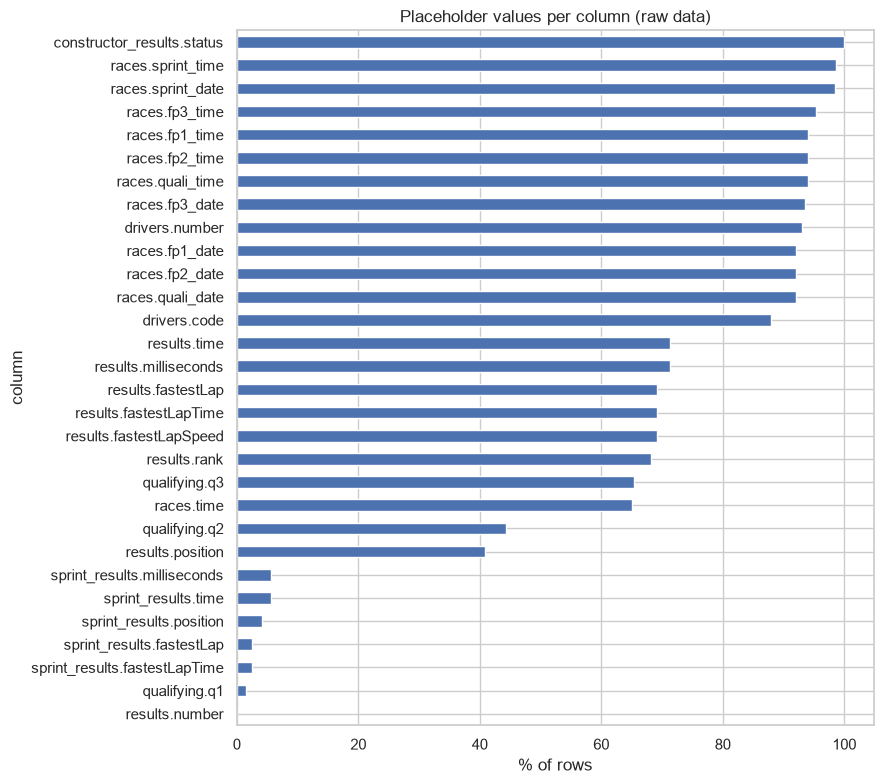

In [4]:
audit = []
for name, df in raw.items():
    for col in df.columns:
        missing = df[col].astype(str).isin([r"\N", ""]).mean() * 100
        if missing > 0:
            audit.append({"column": f"{name}.{col}", "% placeholder": round(missing, 1)})
audit = pd.DataFrame(audit).sort_values("% placeholder")

audit.plot.barh(x="column", y="% placeholder", figsize=(9, 8), legend=False,
                title="Placeholder values per column (raw data)")
plt.xlabel("% of rows")
plt.tight_layout()
plt.show()

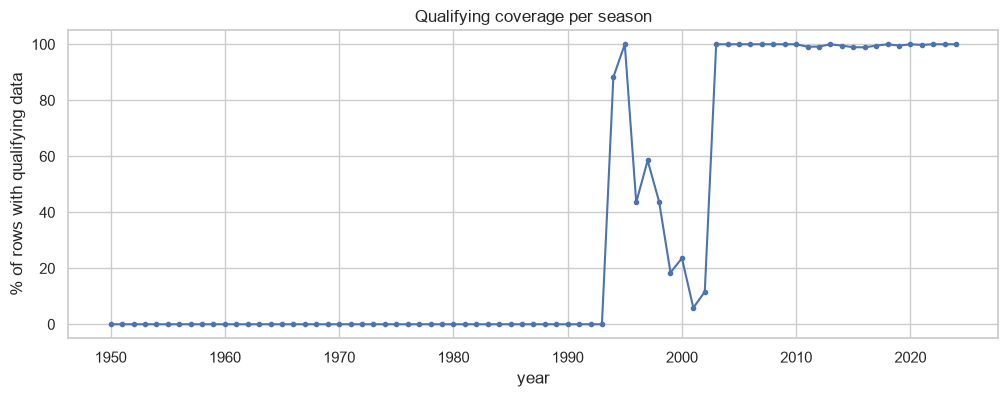

year,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004
% with qualifying,0.0,88.0,100.0,44.0,59.0,44.0,18.0,24.0,6.0,12.0,100.0,100.0


In [5]:
race_year = raw["races"].set_index("raceId")["year"]

cov = raw["results"][["raceId", "driverId"]].merge(
    raw["qualifying"][["raceId", "driverId"]], how="left", indicator=True)
cov["year"] = cov["raceId"].map(race_year)
quali_cov = (cov["_merge"] == "both").groupby(cov["year"]).mean() * 100

quali_cov.plot(marker="o", markersize=3, figsize=(12, 4), title="Qualifying coverage per season")
plt.ylabel("% of rows with qualifying data")
plt.show()
quali_cov.loc[1993:2004].round(0).to_frame("% with qualifying").T

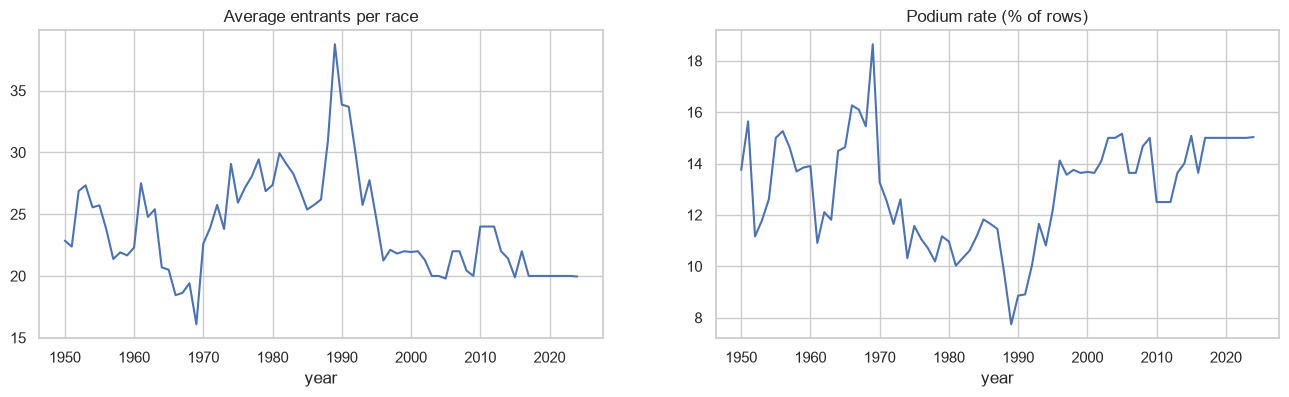

Overall podium rate: 12.7%  (3,397 of 26,759 rows)


In [6]:
r = raw["results"].copy()
r["year"] = r["raceId"].map(race_year)
r["podium"] = (r["positionOrder"] <= 3).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
r.groupby("raceId").size().groupby(race_year).mean().plot(ax=axes[0], title="Average entrants per race")
(r.groupby("year")["podium"].mean() * 100).plot(ax=axes[1], title="Podium rate (% of rows)")
plt.show()
print(f"Overall podium rate: {r['podium'].mean():.1%}  ({r['podium'].sum():,} of {len(r):,} rows)")

In [7]:
res_raw = raw["results"]
dups = res_raw.duplicated(["raceId", "driverId"], keep=False)
print("Rows in duplicate (raceId, driverId) pairs:", dups.sum())
print("Rows with grid = 0:", (res_raw["grid"] == 0).sum())
res_raw.loc[~res_raw["positionText"].str.isdigit(), "positionText"].value_counts().to_frame("rows")

Rows in duplicate (raceId, driverId) pairs: 176
Rows with grid = 0: 1638


,rows
positionText,
R,8897
F,1368
W,336
N,190
D,151
E,9


## 2. Cleaning

Placeholders converted to NaN, dates and lap times typed (times in seconds), 2 impossible qualifying times removed, and all primary keys and 23 foreign-key links verified.

In [8]:
clean = {name: pd.read_csv(DATA_RAW / f"{name}.csv", na_values=[r"\N", ""], keep_default_na=False)
         for name in TABLES}

pd.DataFrame({
    "placeholders (raw)": {n: int(raw[n].astype(str).isin([r"\N", ""]).sum().sum()) for n in TABLES},
    "NaN (clean)": {n: int(clean[n].isna().sum().sum()) for n in TABLES},
})

,placeholders (raw),NaN (clean)
circuits,0,0
constructors,0,0
constructor_results,12608,12608
constructor_standings,0,0
drivers,1559,1559
driver_standings,0,0
races,11349,11349
results,122887,122887
qualifying,11668,11668
lap_times,0,0


In [9]:
[f"{n}.{c}" for n in TABLES for c in clean[n].columns if raw[n][c].dtype != clean[n][c].dtype]

['drivers.number',
 'results.number',
 'results.position',
 'results.milliseconds',
 'results.fastestLap',
 'results.rank',
 'results.fastestLapSpeed',
 'sprint_results.position',
 'sprint_results.milliseconds',
 'sprint_results.fastestLap']

Largest difference vs milliseconds: 0.0


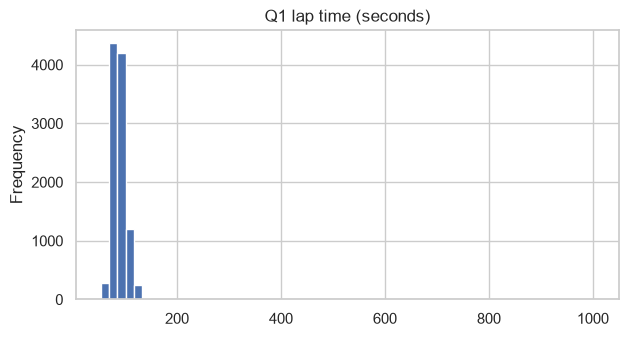

In [10]:
clean["races"]["date"] = pd.to_datetime(clean["races"]["date"])
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"])

def time_to_seconds(value):
    if pd.isna(value):
        return np.nan
    seconds = 0.0
    for part in str(value).split(":"):
        seconds = seconds * 60 + float(part)
    return seconds

check = clean["lap_times"]["time"].map(time_to_seconds) * 1000 - clean["lap_times"]["milliseconds"]
print("Largest difference vs milliseconds:", round(check.abs().max(), 6))

for col in ["q1", "q2", "q3"]:
    clean["qualifying"][f"{col}_sec"] = clean["qualifying"][col].map(time_to_seconds)
clean["results"]["fastestLapTime_sec"] = clean["results"]["fastestLapTime"].map(time_to_seconds)

clean["qualifying"]["q1_sec"].plot.hist(bins=60, figsize=(7, 3.5), title="Q1 lap time (seconds)")
plt.show()

In [11]:
q = clean["qualifying"]
for col in ["q1_sec", "q2_sec", "q3_sec"]:
    too_slow = q[col] > 1.5 * q.groupby("raceId")[col].transform("min")
    print(col, "- times removed:", too_slow.sum(), q.loc[too_slow, ["raceId", "driverId", col]].values.tolist())
    q.loc[too_slow, col] = np.nan

q1_sec - times removed: 1 [[255.0, 87.0, 1002.64]]
q2_sec - times removed: 1 [[1107.0, 815.0, 126.688]]
q3_sec - times removed: 0 []


In [12]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"], "results": ["resultId"],
    "sprint_results": ["resultId"], "qualifying": ["qualifyId"], "driver_standings": ["driverStandingsId"],
    "constructor_standings": ["constructorStandingsId"], "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pd.DataFrame({
    "missing keys": {t: int(clean[t][k].isna().any(axis=1).sum()) for t, k in PRIMARY_KEYS.items()},
    "duplicate keys": {t: int(clean[t].duplicated(k).sum()) for t, k in PRIMARY_KEYS.items()},
})

,missing keys,duplicate keys
circuits,0,0
constructors,0,0
drivers,0,0
races,0,0
seasons,0,0
status,0,0
results,0,0
sprint_results,0,0
qualifying,0,0
driver_standings,0,0


In [13]:
FOREIGN_KEYS = [("races", "circuitId", "circuits"), ("races", "year", "seasons")]
for child in ["results", "sprint_results", "qualifying", "driver_standings", "constructor_standings",
              "constructor_results", "lap_times", "pit_stops"]:
    for key, parent in [("raceId", "races"), ("driverId", "drivers"),
                        ("constructorId", "constructors"), ("statusId", "status")]:
        if key in clean[child].columns:
            FOREIGN_KEYS.append((child, key, parent))

orphans = {f"{child}.{key} -> {parent}": int((~clean[child][key].isin(clean[parent][key])).sum())
           for child, key, parent in FOREIGN_KEYS}
print(f"{sum(v == 0 for v in orphans.values())} of {len(orphans)} links have no orphans")
pd.Series(orphans, name="orphans").to_frame()

23 of 23 links have no orphans


,orphans
races.circuitId -> circuits,0
races.year -> seasons,0
results.raceId -> races,0
results.driverId -> drivers,0
results.constructorId -> constructors,0
results.statusId -> status,0
sprint_results.raceId -> races,0
sprint_results.driverId -> drivers,0
sprint_results.constructorId -> constructors,0
sprint_results.statusId -> status,0


## 3. Grain + EDA after cleaning

We exclude the Indianapolis 500 and drivers who never started, keep grid = 0 rows as pit-lane starts, and keep the best `positionOrder` row for shared drives, giving 24,571 unique driver-race rows. The podium rate goes from 12.7% to 13.7% after cleaning.

In [14]:
base = (clean["results"]
        .merge(clean["races"][["raceId", "year", "round", "date", "circuitId", "name"]], on="raceId")
        .merge(clean["status"], on="statusId")
        .rename(columns={"name": "race_name"}))
base["podium"] = (base["positionOrder"] <= 3).astype(int)
funnel = {"All result rows": len(base)}

In [15]:
is_indy = base["race_name"] == "Indianapolis 500"
indy_drivers = set(base.loc[is_indy, "driverId"])
other_drivers = set(base.loc[~is_indy, "driverId"])
print(f"Indy 500: {base.loc[is_indy, 'raceId'].nunique()} races, {is_indy.sum()} rows, {len(indy_drivers)} drivers")
print("Indy drivers who ever entered another championship race:", len(indy_drivers & other_drivers))

base = base[~is_indy]
funnel["Without Indianapolis 500"] = len(base)

Indy 500: 11 races, 405 rows, 107 drivers
Indy drivers who ever entered another championship race: 4


In [16]:
non_starter = base["positionText"].isin(["F", "W"]) | ((base["grid"] == 0) & (base["laps"] == 0))
print("Non-starter rows:", non_starter.sum(), "  podiums among them:", base.loc[non_starter, "podium"].sum())
print(base.loc[non_starter, "status"].value_counts().head(4).to_string())

base = base[~non_starter]
funnel["Without non-starters"] = len(base)

g0 = base[base["grid"] == 0]
print(f"\nRemaining grid = 0 rows: {len(g0)}, all completed laps: {(g0['laps'] > 0).all()}, "
      f"seasons {g0['year'].min()}-{g0['year'].max()}")

Non-starter rows: 1719   podiums among them: 0
status
Did not qualify       1025
Did not prequalify     331
Withdrew               228
Accident                29

Remaining grid = 0 rows: 72, all completed laps: True, seasons 2015-2024


In [17]:
dup = base[base.duplicated(["raceId", "driverId"], keep=False)]
print(f"Duplicate pairs: {dup.groupby(['raceId', 'driverId']).ngroups}, rows: {len(dup)}, "
      f"seasons {dup['year'].min()}-{dup['year'].max()}")

both_nonzero = dup.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).all())
print("Pairs where both rows have a non-zero grid:", both_nonzero.sum(), "of", len(both_nonzero))

dup.loc[(dup["year"] == 1957) & (dup["race_name"] == "British Grand Prix"),
        ["driverId", "number", "grid", "positionText", "positionOrder", "status"]]

Duplicate pairs: 61, rows: 125, seasons 1950-1964
Pairs where both rows have a non-zero grid: 61 of 61


,driverId,number,grid,positionText,positionOrder,status
18805,479,20.0,3,1,1,Finished
18815,581,12.0,8,R,11,Water leak
18816,475,18.0,1,R,12,Engine
20288,475,20.0,3,1,1,Finished
20289,581,16.0,9,4,4,+2 Laps
20290,479,18.0,1,R,12,Engine


In [18]:
base = (base.sort_values(["raceId", "driverId", "positionOrder"])
            .drop_duplicates(["raceId", "driverId"])
            .reset_index(drop=True))
funnel["One row per driver per race"] = len(base)

assert not base.duplicated(["raceId", "driverId"]).any()
pd.Series(funnel, name="rows").to_frame()

,rows
All result rows,26759
Without Indianapolis 500,26354
Without non-starters,24635
One row per driver per race,24571


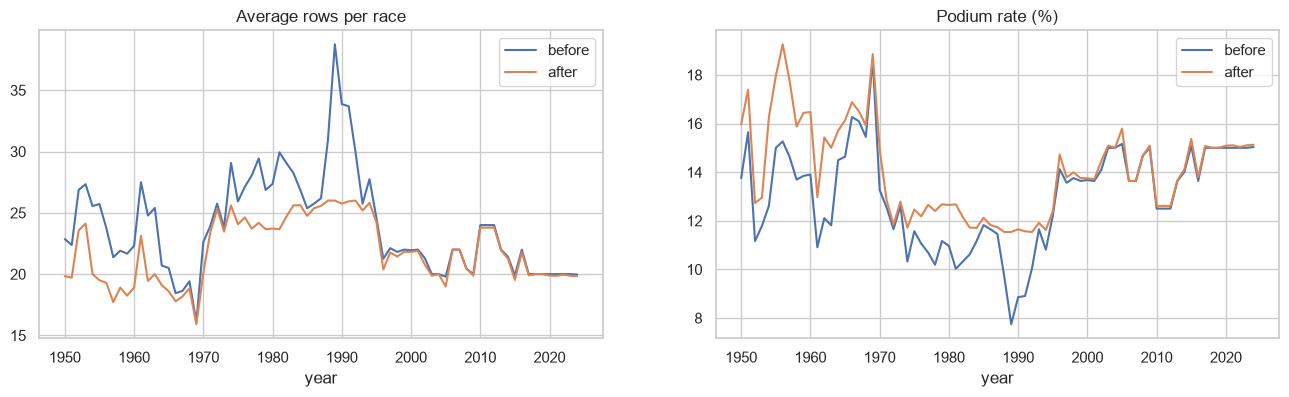

Podium rate before: 12.7%   after: 13.7%


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
r.groupby("raceId").size().groupby(race_year).mean().plot(ax=axes[0], label="before")
base.groupby("raceId").size().groupby(race_year).mean().plot(ax=axes[0], label="after")
(r.groupby("year")["podium"].mean() * 100).plot(ax=axes[1], label="before")
(base.groupby("year")["podium"].mean() * 100).plot(ax=axes[1], label="after")
axes[0].set_title("Average rows per race")
axes[1].set_title("Podium rate (%)")
axes[0].legend(); axes[1].legend()
plt.show()
print(f"Podium rate before: {r['podium'].mean():.1%}   after: {base['podium'].mean():.1%}")

## 4. Data-engineering questions

All three questions use the cleaned driver-race table joined with the other tables.

### Q1. Which circuits convert a front-row start into a podium most often, and does that ranking change after 2014?

Best converters in 2014-2024 are Monaco (90%), Suzuka (89%) and Yas Marina (86%), compared with Magny-Cours, Istanbul Park, Monza and Monaco in 2003-2013. The ranking changed after 2014 (rank correlation 0.36 on grid, 0.54 on qualifying), and the grid and qualifying definitions give almost the same ranking (0.92).

In [20]:
q1 = (base.merge(clean["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"}),
                 on=["raceId", "driverId"], how="left")
          .merge(clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId"))
q1 = q1[q1["year"] >= 2003].copy()
q1["era"] = np.where(q1["year"] >= 2014, "2014-2024", "2003-2013")
q1["front_row_grid"] = q1["grid"].isin([1, 2])
q1["front_row_quali"] = q1["quali_pos"].isin([1, 2])

display(pd.crosstab(q1["front_row_quali"], q1["front_row_grid"]))
pd.DataFrame({
    "grid conversion %": q1[q1["front_row_grid"]].groupby("era")["podium"].mean() * 100,
    "quali conversion %": q1[q1["front_row_quali"]].groupby("era")["podium"].mean() * 100,
}).round(1)

front_row_grid,False,True
front_row_quali,,
False,8022,36
True,36,815


,grid conversion %,quali conversion %
era,,
2003-2013,68.3,67.6
2014-2024,76.2,74.2


In [21]:
def conversion_by_circuit(flag):
    front = q1[q1[flag]]
    t = front.groupby(["circuit", "era"]).agg(races=("raceId", "nunique"), podiums=("podium", "sum"),
                                              starts=("podium", "size"))
    t["conversion_%"] = (100 * t["podiums"] / t["starts"]).round(1)
    return t[t["races"] >= 5]

conv_grid = conversion_by_circuit("front_row_grid")
conv_quali = conversion_by_circuit("front_row_quali")

for era in ["2003-2013", "2014-2024"]:
    print(f"Top 5 circuits {era}:")
    display(conv_grid.xs(era, level="era").sort_values("conversion_%", ascending=False).head(5))

Top 5 circuits 2003-2013:


,races,podiums,starts,conversion_%
circuit,,,,
Circuit de Nevers Magny-Cours,6,11,12,91.7
Istanbul Park,7,11,14,78.6
Autodromo Nazionale di Monza,11,17,22,77.3
Circuit de Monaco,11,17,22,77.3
Silverstone Circuit,11,16,22,72.7


Top 5 circuits 2014-2024:


,races,podiums,starts,conversion_%
circuit,,,,
Circuit de Monaco,10,17,19,89.5
Suzuka Circuit,9,16,18,88.9
Yas Marina Circuit,11,19,22,86.4
Circuit de Spa-Francorchamps,11,18,22,81.8
Circuit de Barcelona-Catalunya,11,18,22,81.8


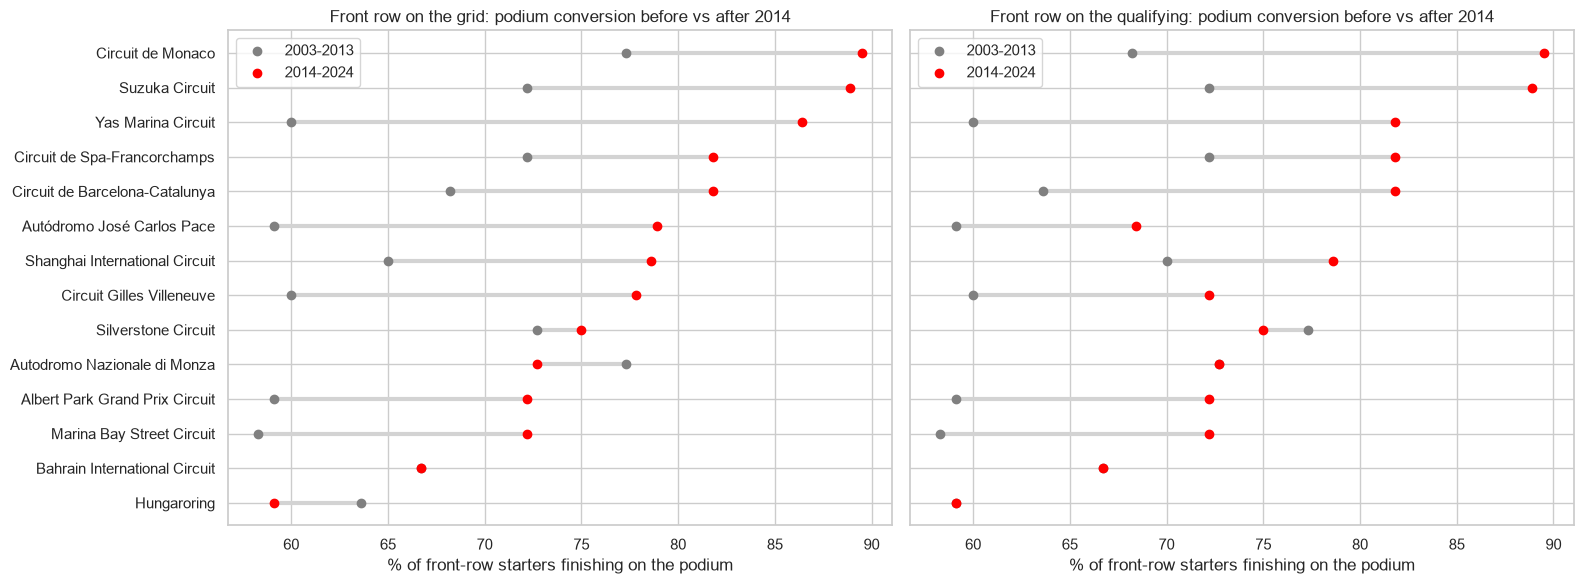

Rank correlation between eras (grid): 0.36
Rank correlation between eras (qualifying): 0.54
Rank correlation grid-based vs qualifying-based: 0.92


In [22]:
grid_both = conv_grid["conversion_%"].unstack("era").dropna().sort_values("2014-2024")
quali_both = conv_quali["conversion_%"].unstack("era").reindex(grid_both.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (label, both) in zip(axes, [("grid", grid_both), ("qualifying", quali_both)]):
    ax.hlines(both.index, both["2003-2013"], both["2014-2024"], color="lightgray", linewidth=3)
    ax.scatter(both["2003-2013"], both.index, color="gray", label="2003-2013", zorder=3)
    ax.scatter(both["2014-2024"], both.index, color="red", label="2014-2024", zorder=3)
    ax.set_title(f"Front row on the {label}: podium conversion before vs after 2014")
    ax.set_xlabel("% of front-row starters finishing on the podium")
    ax.legend()
plt.tight_layout()
plt.show()

for label, both in [("grid", grid_both), ("qualifying", quali_both.dropna())]:
    print(f"Rank correlation between eras ({label}): {stats.spearmanr(both['2003-2013'], both['2014-2024'])[0]:.2f}")

compare = conv_grid[["conversion_%"]].join(conv_quali[["conversion_%"]], rsuffix="_quali").dropna()
print("Rank correlation grid-based vs qualifying-based:", round(stats.spearmanr(compare.iloc[:, 0], compare.iloc[:, 1])[0], 2))

### Q2. Do drivers podium more often at home, after controlling for starting position?

No. Within the same grid band home and away podium rates are similar, and the logistic regression gives a home odds ratio of 0.96 (95% CI 0.81-1.14, p = 0.66).

Home rows: 1,928 of 24,499
Raw podium rate (%): {0: 13.9, 1: 11.9}


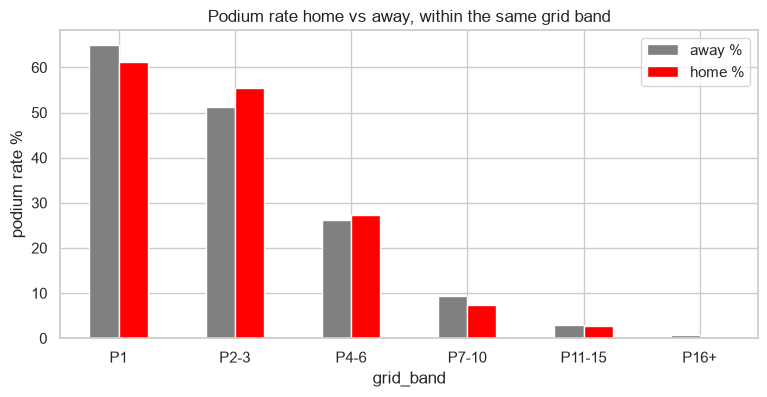

,away %,home %
grid_band,,
P1,65.0,61.3
P2-3,51.1,55.4
P4-6,26.2,27.2
P7-10,9.4,7.4
P11-15,3.0,2.7
P16+,0.7,0.3


In [23]:
NATIONALITY_TO_COUNTRY = {
    "American": ["USA"], "American-Italian": ["USA", "Italy"], "Argentine": ["Argentina"],
    "Argentinian": ["Argentina"], "Argentine-Italian": ["Argentina", "Italy"], "Australian": ["Australia"],
    "Austrian": ["Austria"], "Belgian": ["Belgium"], "Brazilian": ["Brazil"], "British": ["UK"],
    "Canadian": ["Canada"], "Chinese": ["China"], "Dutch": ["Netherlands"], "East German": ["Germany"],
    "French": ["France"], "German": ["Germany"], "Hungarian": ["Hungary"], "Indian": ["India"],
    "Italian": ["Italy"], "Japanese": ["Japan"], "Malaysian": ["Malaysia"], "Mexican": ["Mexico"],
    "Monegasque": ["Monaco"], "Portuguese": ["Portugal"], "Russian": ["Russia"],
    "South African": ["South Africa"], "Spanish": ["Spain"], "Swedish": ["Sweden"], "Swiss": ["Switzerland"],
    "Chilean": [], "Colombian": [], "Czech": [], "Danish": [], "Finnish": [], "Indonesian": [], "Irish": [],
    "Liechtensteiner": [], "New Zealander": [], "Polish": [], "Rhodesian": [], "Thai": [],
    "Uruguayan": [], "Venezuelan": [],
}

q2 = (base.merge(clean["drivers"][["driverId", "nationality"]], on="driverId")
          .merge(clean["circuits"][["circuitId", "country"]], on="circuitId"))
q2["nationality"] = q2["nationality"].str.strip()
q2["country"] = q2["country"].replace({"United States": "USA"})
assert q2["nationality"].isin(NATIONALITY_TO_COUNTRY.keys()).all()

q2["home"] = [c in NATIONALITY_TO_COUNTRY[n] for n, c in zip(q2["nationality"], q2["country"])]
q2["home"] = q2["home"].astype(int)
q2 = q2[q2["grid"] > 0].copy()
q2["grid_band"] = pd.cut(q2["grid"], bins=[0, 1, 3, 6, 10, 15, 100],
                         labels=["P1", "P2-3", "P4-6", "P7-10", "P11-15", "P16+"])

print(f"Home rows: {q2['home'].sum():,} of {len(q2):,}")
print("Raw podium rate (%):", (q2.groupby("home")["podium"].mean() * 100).round(1).to_dict())

band = q2.groupby(["grid_band", "home"], observed=True)["podium"].mean().unstack() * 100
band.columns = ["away %", "home %"]
band.plot.bar(rot=0, color=["gray", "red"], figsize=(9, 4),
              title="Podium rate home vs away, within the same grid band")
plt.ylabel("podium rate %")
plt.show()
band.round(1)

In [24]:
fit = smf.logit("podium ~ home + C(grid_band)", data=q2).fit(disp=0)
low, high = np.exp(fit.conf_int().loc["home"])
print(f"Home odds ratio: {np.exp(fit.params['home']):.2f}  (95% CI {low:.2f}-{high:.2f}, p = {fit.pvalues['home']:.2f})")

Home odds ratio: 0.96  (95% CI 0.81-1.14, p = 0.66)


### Q3. Which constructors have the highest mechanical-retirement rate in 2014-2021 vs 2022-2024?

Lotus F1, Toro Rosso and McLaren had the highest rates in 2014-2021, and Alfa Romeo, Alpine and AlphaTauri in 2022-2024. Overall the mechanical-retirement rate fell from 9.5% to 5.8% of starts.

In [25]:
MECHANICAL = {
    "Engine", "Gearbox", "Suspension", "Electrical", "Transmission", "Brakes", "Clutch", "Fuel system",
    "Turbo", "Hydraulics", "Overheating", "Ignition", "Oil leak", "Throttle", "Halfshaft", "Wheel",
    "Oil pressure", "Differential", "Fuel pump", "Handling", "Steering", "Radiator", "Fuel leak",
    "Power Unit", "Injection", "Fuel pressure", "Wheel bearing", "Water leak", "Alternator", "Mechanical",
    "Chassis", "Exhaust", "Driveshaft", "Battery", "Heat shield fire", "Axle", "Power loss", "Distributor",
    "Oil pump", "Electronics", "Broken wing", "Oil pipe", "Rear wing", "Vibrations", "Water pressure",
    "Wheel nut", "Magneto", "Water pump", "Technical", "Pneumatics", "Fuel", "ERS", "Undertray",
    "Wheel rim", "Spark plugs", "Fuel pipe", "Water pipe", "Track rod", "Fire", "Drivetrain",
    "Supercharger", "Driver Seat", "Seat", "Engine fire", "Oil line", "Launch control", "Crankshaft",
    "Safety belt", "CV joint", "Engine misfire", "Brake duct", "Cooling system", "Tyre",
}
ACCIDENT_OR_DRIVER = {"Accident", "Collision", "Spun off", "Collision damage", "Damage", "Debris",
                      "Puncture", "Tyre puncture", "Front wing", "Fatal accident", "Stalled"}
OTHER = {"Not classified", "Disqualified", "Excluded", "Withdrew", "Retired", "Physical", "Driver unwell",
         "Injury", "Injured", "Eye injury", "Illness", "Out of fuel", "Fuel rig", "Refuelling", "Not restarted"}

def status_category(status):
    if status == "Finished" or status.startswith("+"):
        return "finished"
    if status in MECHANICAL:
        return "mechanical"
    if status in ACCIDENT_OR_DRIVER:
        return "accident / driver"
    if status in OTHER:
        return "other"
    return "UNMAPPED"

base["status_group"] = base["status"].map(status_category)
assert (base["status_group"] != "UNMAPPED").all()
base["status_group"].value_counts()

status_group
finished             14956
mechanical            6314
accident / driver     2721
other                  580
Name: count, dtype: int64

Overall rate per era (%): {'2014-2021': 9.5, '2022-2024': 5.8}


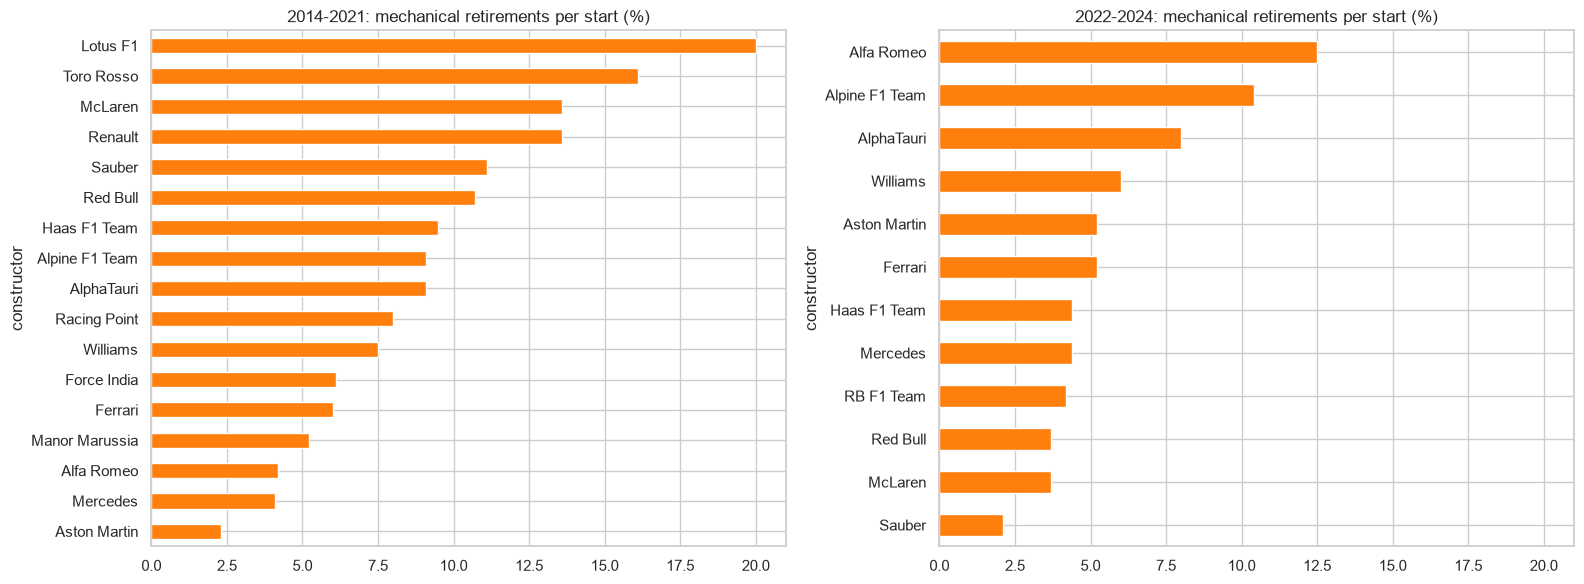

starts                mech              rate_%          
era            2014-2021 2022-2024 2014-2021 2022-2024 2014-2021 2022-2024
constructor                                                               
Alfa Romeo         120.0      88.0       5.0      11.0       4.2      12.5
AlphaTauri          77.0      88.0       7.0       7.0       9.1       8.0
Alpine F1 Team      44.0     135.0       4.0      14.0       9.1      10.4
Aston Martin        44.0     134.0       1.0       7.0       2.3       5.2
Ferrari            317.0     134.0      19.0       7.0       6.0       5.2
Force India        198.0       NaN      12.0       NaN       6.1       NaN
Haas F1 Team       241.0     135.0      23.0       6.0       9.5       4.4
Lotus F1            75.0       NaN      15.0       NaN      20.0       NaN
Manor Marussia      77.0       NaN       4.0       NaN       5.2       NaN
McLaren            316.0     136.0      43.0       5.0      13.6       3.7
Mercedes           320.0     136.0      13.0       6.0       4.1       4.4
Racing Point        75.0       NaN       6.0       NaN       8.0       NaN
Red Bull           318.0     136.0      34.0       5.0      10.7       3.7
Renault            199.0       NaN      27.0       NaN      13.6       NaN
Sauber             199.0      48.0      22.0       1.0      11.1       2.1
Toro Rosso         242.0       NaN      39.0       NaN      16.1       NaN
Williams           319.0     134.0      24.0       8.0       7.5       6.0
RB F1 Team           NaN      48.0       NaN       2.0       NaN       4.2

In [26]:
q3 = base[base["year"] >= 2014].merge(
    clean["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId")
q3["era"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
q3["mechanical"] = (q3["status_group"] == "mechanical").astype(int)

rates = q3.groupby(["era", "constructor"]).agg(starts=("mechanical", "size"), mech=("mechanical", "sum"))
rates = rates[rates["starts"] >= 40]
rates["rate_%"] = (100 * rates["mech"] / rates["starts"]).round(1)
print("Overall rate per era (%):", (q3.groupby("era")["mechanical"].mean() * 100).round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
for ax, era in zip(axes, ["2014-2021", "2022-2024"]):
    rates.loc[era, "rate_%"].sort_values().plot.barh(ax=ax, color="tab:orange", title=f"{era}: mechanical retirements per start (%)")
plt.tight_layout()
plt.show()
rates.unstack("era").round(1)

## 5. Feature engineering

All features use only information available before the race (previous races for form, standings after the previous race), confirmed by an automatic leakage test on 20,378 pre-2015 rows.

In [27]:
def past_mean(values, groups, window):
    return values.groupby(groups).transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

def past_sum(values, groups, window):
    return values.groupby(groups).transform(lambda s: s.shift(1).rolling(window, min_periods=1).sum())

def build_features(base_df):
    df = base_df.sort_values(["date", "raceId"]).reset_index(drop=True)
    f = df[["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date", "podium"]].copy()

    f["field_size"] = f.groupby("raceId")["driverId"].transform("size")
    f["grid_pos"] = df["grid"].where(df["grid"] > 0, f["field_size"])

    q = clean["qualifying"][["raceId", "driverId", "position", "q1_sec"]].rename(columns={"position": "quali_pos"})
    q["q1_gap_pct"] = (q["q1_sec"] / q.groupby("raceId")["q1_sec"].transform("min") - 1) * 100
    f = f.merge(q[["raceId", "driverId", "quali_pos", "q1_gap_pct"]], on=["raceId", "driverId"], how="left")
    f["has_quali"] = f["quali_pos"].notna().astype(int)
    f["grid_penalty"] = f["grid_pos"] - f["quali_pos"]

    f["drv_podium_rate_last5"] = past_mean(f["podium"], f["driverId"], 5)
    f["drv_avg_finish_last5"] = past_mean(df["positionOrder"], f["driverId"], 5)
    f["drv_races_before"] = f.groupby("driverId").cumcount()
    f["drv_career_podium_rate"] = f.groupby("driverId")["podium"].transform(lambda s: s.shift(1).expanding().mean())

    f["_finish"] = df["positionOrder"]
    f["_mech"] = (df["status_group"] == "mechanical").astype(int)
    con = (f.groupby(["constructorId", "raceId", "date"], as_index=False)
            .agg(podiums=("podium", "sum"), cars=("podium", "size"), best=("_finish", "min"), mech=("_mech", "sum"))
            .sort_values("date"))
    team = con["constructorId"]
    con["con_podium_rate_last5"] = past_sum(con["podiums"], team, 5) / past_sum(con["cars"], team, 5)
    con["con_best_finish_last5"] = past_mean(con["best"], team, 5)
    con["con_mech_dnf_rate_last10"] = past_sum(con["mech"], team, 10) / past_sum(con["cars"], team, 10)
    f = f.merge(con.drop(columns=["date", "podiums", "cars", "best", "mech"]), on=["constructorId", "raceId"], how="left")

    races = clean["races"].sort_values(["year", "round"])
    prev_race = dict(zip(races["raceId"], races.groupby("year")["raceId"].shift(1)))
    f["prev_raceId"] = f["raceId"].map(prev_race)

    ds = clean["driver_standings"].rename(columns={"raceId": "prev_raceId", "position": "drv_champ_pos_before",
                                                   "wins": "drv_season_wins_before"})
    cs = clean["constructor_standings"].rename(columns={"raceId": "prev_raceId", "position": "con_champ_pos_before"})
    f = f.merge(ds[["prev_raceId", "driverId", "drv_champ_pos_before", "drv_season_wins_before"]],
                on=["prev_raceId", "driverId"], how="left")
    f = f.merge(cs[["prev_raceId", "constructorId", "con_champ_pos_before"]],
                on=["prev_raceId", "constructorId"], how="left")
    f["drv_season_wins_before"] = f["drv_season_wins_before"].fillna(0)

    return f.drop(columns=["_finish", "_mech", "prev_raceId"])

CANDIDATES = ["grid_pos", "quali_pos", "q1_gap_pct", "grid_penalty", "has_quali",
              "drv_podium_rate_last5", "drv_avg_finish_last5", "drv_races_before", "drv_career_podium_rate",
              "con_podium_rate_last5", "con_best_finish_last5", "con_mech_dnf_rate_last10",
              "drv_champ_pos_before", "drv_season_wins_before", "con_champ_pos_before", "field_size"]

features = build_features(base)
assert len(features) == len(base) and not features.duplicated(["raceId", "driverId"]).any()
print(f"{len(features):,} rows, {len(CANDIDATES)} candidate features")

24,571 rows, 16 candidate features


In [28]:
features.loc[features["driverId"] == 1, ["date", "podium", "drv_races_before", "drv_podium_rate_last5",
                                         "drv_champ_pos_before"]].head(5)

,date,podium,drv_races_before,drv_podium_rate_last5,drv_champ_pos_before
17097,2007-03-18,1,0,NaN,NaN
17119,2007-04-08,1,1,1.0,3.0
17141,2007-04-15,1,2,1.0,3.0
17163,2007-05-13,1,3,1.0,3.0
17185,2007-05-27,1,4,1.0,1.0


In [29]:
cutoff = pd.Timestamp("2015-01-01")
past_only = build_features(base[base["date"] < cutoff]).set_index(["raceId", "driverId"])[CANDIDATES].sort_index()
full = features[features["date"] < cutoff].set_index(["raceId", "driverId"])[CANDIDATES].sort_index()
pd.testing.assert_frame_equal(full, past_only)
print(f"Leakage test passed: {len(full):,} pre-2015 rows identical with and without future races.")

Leakage test passed: 20,378 pre-2015 rows identical with and without future races.


### Feature EDA (training seasons up to 2019)

Candidate features are screened on the training seasons only, using univariate ROC-AUC, effect plots and a correlation check.

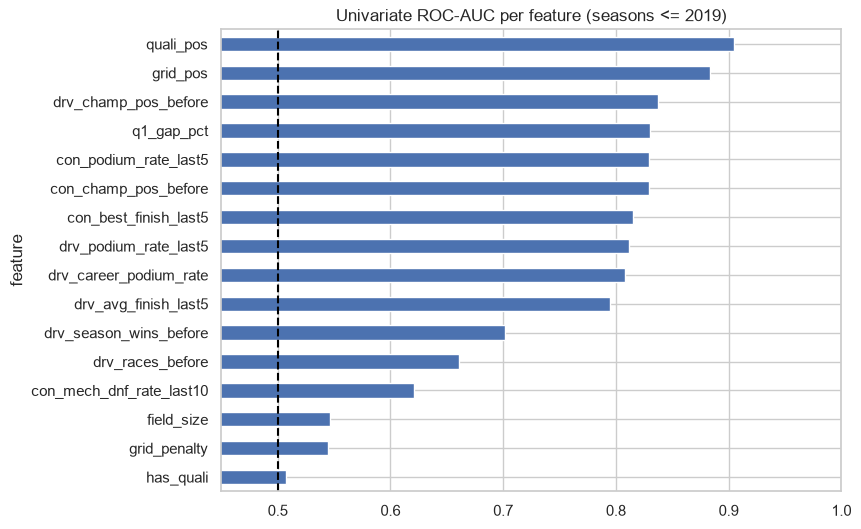

,feature,AUC,% with value
1,quali_pos,0.905,37
0,grid_pos,0.883,100
12,drv_champ_pos_before,0.837,88
2,q1_gap_pct,0.830,36
9,con_podium_rate_last5,0.829,99
14,con_champ_pos_before,0.829,88
10,con_best_finish_last5,0.815,99
5,drv_podium_rate_last5,0.812,97
8,drv_career_podium_rate,0.808,97
6,drv_avg_finish_last5,0.795,97


In [30]:
eda = features[features["year"] <= 2019]

screen = []
for col in CANDIDATES:
    known = eda[col].notna()
    auc = roc_auc_score(eda.loc[known, "podium"], eda.loc[known, col])
    screen.append({"feature": col, "AUC": round(max(auc, 1 - auc), 3), "% with value": round(100 * known.mean())})
screen = pd.DataFrame(screen).sort_values("AUC")

screen.plot.barh(x="feature", y="AUC", xlim=(0.45, 1), legend=False, figsize=(8, 6),
                 title="Univariate ROC-AUC per feature (seasons <= 2019)")
plt.axvline(0.5, color="black", linestyle="--")
plt.show()
screen.sort_values("AUC", ascending=False)

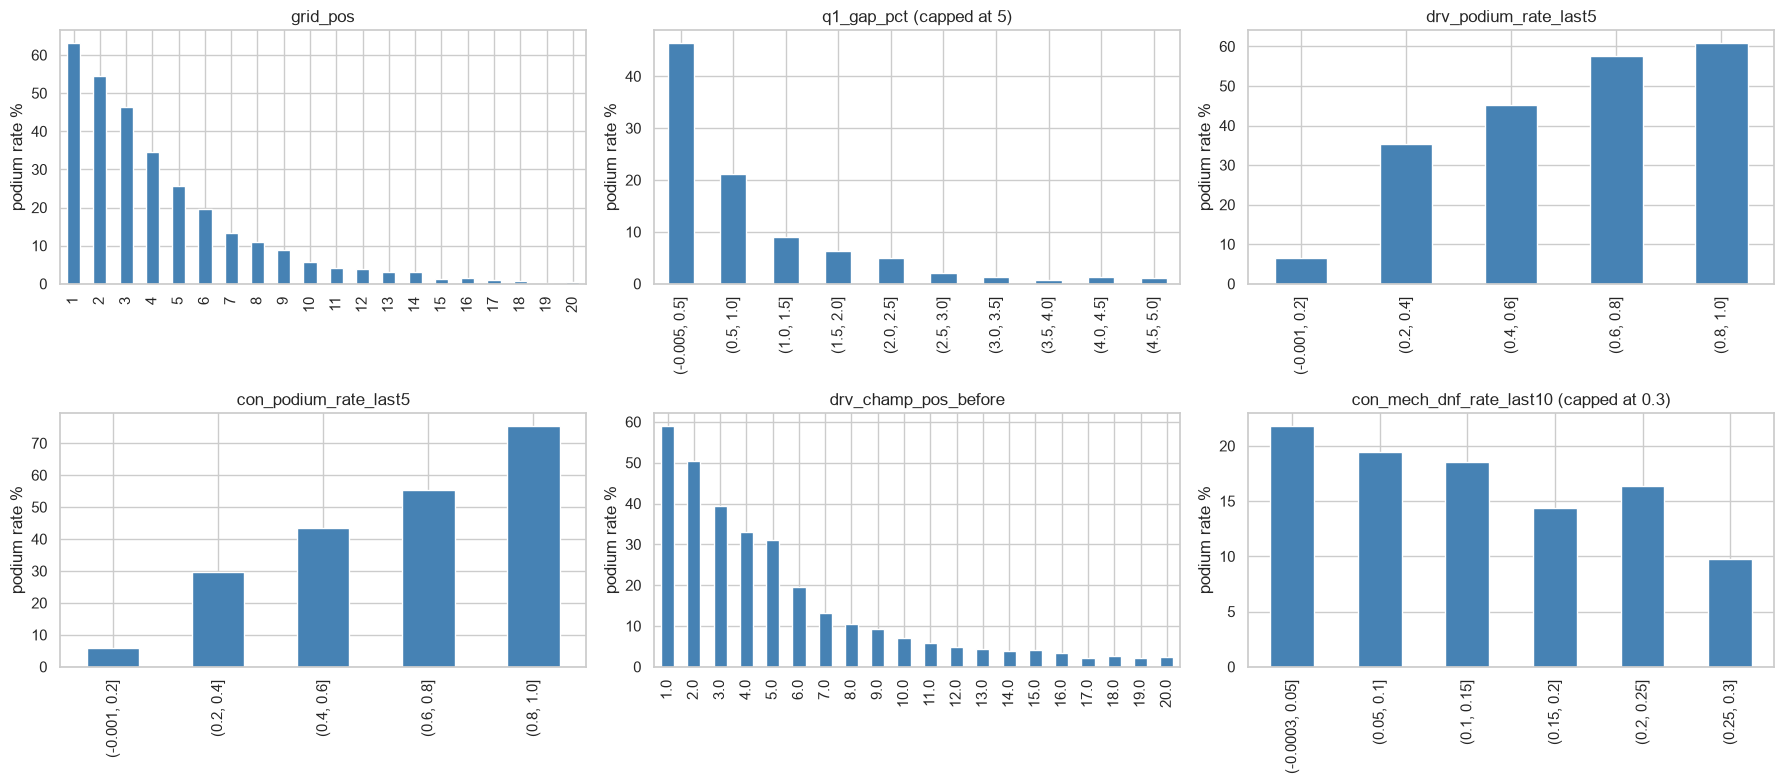

In [31]:
plots = {
    "grid_pos": eda["grid_pos"].clip(upper=20),
    "q1_gap_pct (capped at 5)": pd.cut(eda["q1_gap_pct"].clip(upper=5), 10),
    "drv_podium_rate_last5": pd.cut(eda["drv_podium_rate_last5"], 5),
    "con_podium_rate_last5": pd.cut(eda["con_podium_rate_last5"], 5),
    "drv_champ_pos_before": eda["drv_champ_pos_before"].clip(upper=20),
    "con_mech_dnf_rate_last10 (capped at 0.3)": pd.cut(eda["con_mech_dnf_rate_last10"].clip(upper=0.3), 6),
}
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, (title, groups) in zip(axes.flat, plots.items()):
    (eda.groupby(groups, observed=True)["podium"].mean() * 100).plot.bar(ax=ax, color="steelblue", title=title)
    ax.set_xlabel("")
    ax.set_ylabel("podium rate %")
plt.tight_layout()
plt.show()

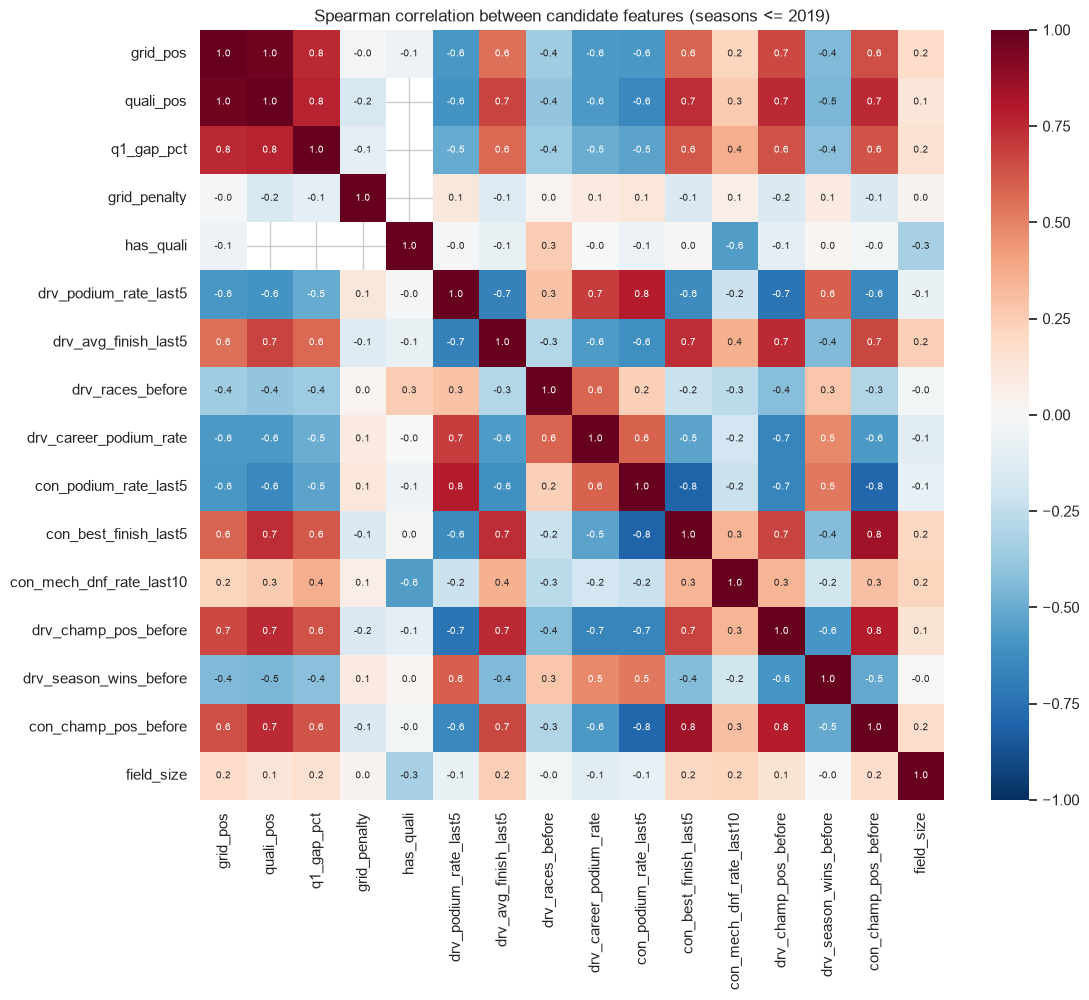

In [32]:
plt.figure(figsize=(12, 10))
sns.heatmap(eda[CANDIDATES].corr(method="spearman"), cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7})
plt.title("Spearman correlation between candidate features (seasons <= 2019)")
plt.show()

In [33]:
same_rows = eda[eda["quali_pos"].notna()]
for col in ["grid_pos", "quali_pos"]:
    print(f"{col}: AUC {roc_auc_score(same_rows['podium'], -same_rows[col]):.3f} on the same {len(same_rows):,} rows")

same_rows = same_rows.assign(
    grid_band=pd.cut(same_rows["grid_pos"], [0, 3, 6, 10, 15, 40], labels=["P1-3", "P4-6", "P7-10", "P11-15", "P16+"]),
    penalised=same_rows["grid_penalty"] >= 3)
(same_rows.groupby(["grid_band", "penalised"], observed=True)["podium"].mean().unstack() * 100).round(1)

grid_pos: AUC 0.904 on the same 8,291 rows
quali_pos: AUC 0.905 on the same 8,291 rows


penalised,False,True
grid_band,,
P1-3,63.1,NaN
P4-6,23.2,11.1
P7-10,6.2,20.6
P11-15,2.0,10.4
P16+,0.8,2.0


### Final feature selection

We keep 15 features in 6 groups and drop `quali_pos`, which duplicates `grid_pos` (correlation 0.98, same AUC). `grid_penalty` is kept because penalised drivers podium more often from the same grid band.

In [34]:
FEATURE_GROUPS = {
    "grid":             ["grid_pos"],
    "qualifying":       ["q1_gap_pct", "grid_penalty", "has_quali"],
    "driver_form":      ["drv_podium_rate_last5", "drv_avg_finish_last5", "drv_races_before", "drv_career_podium_rate"],
    "constructor_form": ["con_podium_rate_last5", "con_best_finish_last5", "con_mech_dnf_rate_last10"],
    "standings":        ["drv_champ_pos_before", "drv_season_wins_before", "con_champ_pos_before"],
    "context":          ["field_size"],
}
FEATURES = [col for group in FEATURE_GROUPS.values() for col in group]
TARGET = "podium"

model_table = features[["raceId", "driverId", "constructorId", "year", "date"] + FEATURES + [TARGET]]
print(f"Modelling table: {len(model_table):,} rows, {len(FEATURES)} features, podium rate {model_table[TARGET].mean():.1%}")
(model_table[FEATURES].isna().mean() * 100).round(1).rename("% missing").to_frame()

Modelling table: 24,571 rows, 15 features, podium rate 13.7%


,% missing
grid_pos,0.0
q1_gap_pct,58.2
grid_penalty,57.6
has_quali,0.0
drv_podium_rate_last5,2.8
drv_avg_finish_last5,2.8
drv_races_before,0.0
drv_career_podium_rate,2.8
con_podium_rate_last5,1.1
con_best_finish_last5,1.1


## 6. Train / validation / test split

Split by season: train up to 2019, validation 2020-2021, test 2022-2024. Models, thresholds and the training window are chosen on validation only.

In [35]:
split = pd.cut(model_table["year"], bins=[0, 2019, 2021, 2100], labels=["train", "validation", "test"])

train = model_table[split == "train"]
val = model_table[split == "validation"]
test = model_table[split == "test"]

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

model_table.groupby(split, observed=True).agg(
    first_season=("year", "min"), last_season=("year", "max"), races=("raceId", "nunique"),
    rows=(TARGET, "size"), podium_rate=(TARGET, "mean"), share_with_qualifying=("has_quali", "mean"),
).round(3)

,first_season,last_season,races,rows,podium_rate,share_with_qualifying
year,,,,,,
train,1950,2019,1007,22444,0.135,0.369
validation,2020,2021,39,775,0.151,0.999
test,2022,2024,68,1352,0.151,1.000


## 7. Models

All models share the same pipeline (median imputation, scaling, model). PR-AUC is the primary metric because podiums are rare, and F1 at the validation-chosen threshold is the secondary metric.

In [36]:
def make_model(classifier):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), classifier)

def best_threshold(y, prob):
    precision, recall, thresholds = precision_recall_curve(y, prob)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[np.argmax(f1[:-1])]

def scores(model, X, y, threshold):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y, prob), "PR-AUC": average_precision_score(y, prob),
            "F1": f1_score(y, pred), "Precision": precision_score(y, pred), "Recall": recall_score(y, pred)}

### 7.1 Baseline (logistic regression) and training-window experiment

Logistic regression is the baseline. Training from 2003 gives the best validation PR-AUC (0.739), so all models are trained on 2003-2019.

In [37]:
window_rows = []
for start in [1950, 1980, 1994, 2003]:
    keep = train["year"] >= start
    model = make_model(LogisticRegression(max_iter=1000)).fit(X_train[keep], y_train[keep])
    prob = model.predict_proba(X_val)[:, 1]
    window_rows.append({"train from": start, "train rows": keep.sum(),
                        "val ROC-AUC": roc_auc_score(y_val, prob), "val PR-AUC": average_precision_score(y_val, prob)})
window = pd.DataFrame(window_rows).set_index("train from")

TRAIN_START = window["val PR-AUC"].idxmax()
keep = train["year"] >= TRAIN_START
X_tr, y_tr = X_train[keep], y_train[keep]
print(f"Chosen training start year: {TRAIN_START} ({len(X_tr):,} rows)")
window.round(3)

Chosen training start year: 2003 (6,782 rows)


,train rows,val ROC-AUC,val PR-AUC
train from,,,
1950,22444,0.929,0.730
1980,15656,0.929,0.731
1994,10091,0.930,0.730
2003,6782,0.929,0.739


### 7.2 Modelling attempts

Random forest, gradient boosting and a shallow neural network (1-2 hidden layers), two settings each, compared with the baseline on validation. None of them beats the baseline on PR-AUC.

In [38]:
fitted, val_rows = {}, []

def try_model(name, classifier):
    fitted[name] = make_model(classifier).fit(X_tr, y_tr)
    prob = fitted[name].predict_proba(X_val)[:, 1]
    f1 = f1_score(y_val, prob >= best_threshold(y_val, prob))
    val_rows.append({"model": name, "val ROC-AUC": roc_auc_score(y_val, prob),
                     "val PR-AUC": average_precision_score(y_val, prob), "val F1": f1})
    return pd.DataFrame(val_rows).set_index("model").round(3)

try_model("Logistic regression", LogisticRegression(max_iter=1000))

,val ROC-AUC,val PR-AUC,val F1
model,,,
Logistic regression,0.929,0.739,0.699


In [39]:
try_model("Random forest (depth 6)", RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEED, n_jobs=-1))
try_model("Random forest (depth 12)", RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1))

,val ROC-AUC,val PR-AUC,val F1
model,,,
Logistic regression,0.929,0.739,0.699
Random forest (depth 6),0.928,0.709,0.714
Random forest (depth 12),0.929,0.714,0.707


In [40]:
try_model("Gradient boosting (slow, shallow)", HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=300, random_state=SEED))
try_model("Gradient boosting (fast, deep)", HistGradientBoostingClassifier(learning_rate=0.1, max_depth=6, max_iter=300, random_state=SEED))

,val ROC-AUC,val PR-AUC,val F1
model,,,
Logistic regression,0.929,0.739,0.699
Random forest (depth 6),0.928,0.709,0.714
Random forest (depth 12),0.929,0.714,0.707
"Gradient boosting (slow, shallow)",0.928,0.707,0.711
"Gradient boosting (fast, deep)",0.918,0.691,0.698


In [41]:
try_model("Neural net (1 layer: 32)", MLPClassifier(hidden_layer_sizes=(32,), early_stopping=True, max_iter=500, random_state=SEED))
try_model("Neural net (2 layers: 64-32)", MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=500, random_state=SEED))

,val ROC-AUC,val PR-AUC,val F1
model,,,
Logistic regression,0.929,0.739,0.699
Random forest (depth 6),0.928,0.709,0.714
Random forest (depth 12),0.929,0.714,0.707
"Gradient boosting (slow, shallow)",0.928,0.707,0.711
"Gradient boosting (fast, deep)",0.918,0.691,0.698
Neural net (1 layer: 32),0.907,0.697,0.715
Neural net (2 layers: 64-32),0.904,0.691,0.697


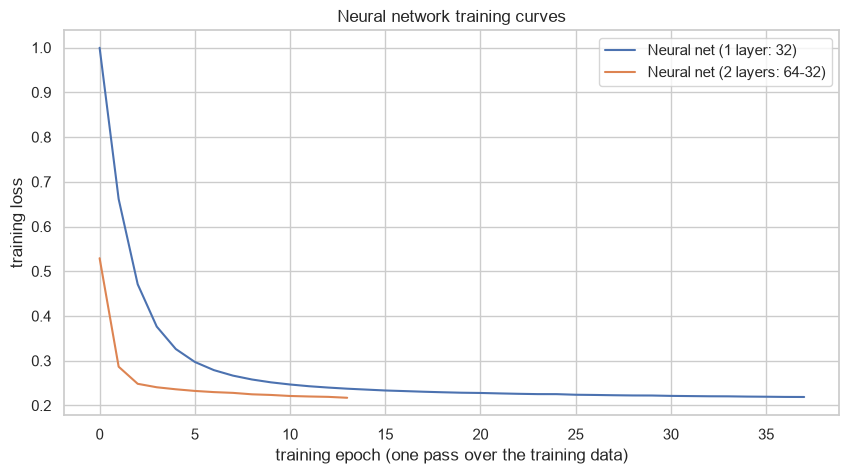

In [42]:
for name in ["Neural net (1 layer: 32)", "Neural net (2 layers: 64-32)"]:
    plt.plot(fitted[name][-1].loss_curve_, label=name)
plt.xlabel("training epoch (one pass over the training data)")
plt.ylabel("training loss")
plt.title("Neural network training curves")
plt.legend()
plt.show()

In [43]:
pd.DataFrame(val_rows).set_index("model").sort_values("val PR-AUC", ascending=False).round(3)

,val ROC-AUC,val PR-AUC,val F1
model,,,
Logistic regression,0.929,0.739,0.699
Random forest (depth 12),0.929,0.714,0.707
Random forest (depth 6),0.928,0.709,0.714
"Gradient boosting (slow, shallow)",0.928,0.707,0.711
Neural net (1 layer: 32),0.907,0.697,0.715
"Gradient boosting (fast, deep)",0.918,0.691,0.698
Neural net (2 layers: 64-32),0.904,0.691,0.697


### 7.3 Final comparison

On the test set gradient boosting reaches PR-AUC 0.721, random forest 0.710, the baseline 0.708 and the neural network 0.660. We keep logistic regression as the final model because it was the best on validation.

In [44]:
val_table = pd.DataFrame(val_rows).set_index("model")
families = ["Logistic regression", "Random forest", "Gradient boosting", "Neural net"]
final_models = {f: val_table[val_table.index.str.startswith(f)]["val PR-AUC"].idxmax() for f in families}

thresholds, report = {}, {"train": {}, "validation": {}, "test": {}}
for family, name in final_models.items():
    model = fitted[name]
    thresholds[family] = float(best_threshold(y_val, model.predict_proba(X_val)[:, 1]))
    report["train"][family] = scores(model, X_tr, y_tr, thresholds[family])
    report["validation"][family] = scores(model, X_val, y_val, thresholds[family])
    report["test"][family] = scores(model, X_test, y_test, thresholds[family])

print("Chosen settings:", final_models)
print("F1 thresholds (chosen on validation):", {k: round(v, 2) for k, v in thresholds.items()})
comparison = pd.concat({split: pd.DataFrame(rows).T for split, rows in report.items()}, axis=1).round(3)
comparison

Chosen settings: {'Logistic regression': 'Logistic regression', 'Random forest': 'Random forest (depth 12)', 'Gradient boosting': 'Gradient boosting (slow, shallow)', 'Neural net': 'Neural net (1 layer: 32)'}
F1 thresholds (chosen on validation): {'Logistic regression': 0.28, 'Random forest': 0.29, 'Gradient boosting': 0.25, 'Neural net': 0.5}


train                                validation         \
                    ROC-AUC PR-AUC     F1 Precision Recall    ROC-AUC PR-AUC   
Logistic regression   0.929  0.685  0.666     0.575  0.792      0.929  0.739   
Random forest         0.979  0.899  0.778     0.679  0.912      0.929  0.714   
Gradient boosting     0.959  0.801  0.716     0.608  0.871      0.928  0.707   
Neural net            0.928  0.679  0.631     0.690  0.580      0.907  0.697   

                                               test                          \
                        F1 Precision Recall ROC-AUC PR-AUC     F1 Precision   
Logistic regression  0.699     0.659  0.744   0.936  0.708  0.685     0.591   
Random forest        0.707     0.667  0.752   0.941  0.710  0.684     0.588   
Gradient boosting    0.711     0.662  0.769   0.939  0.721  0.688     0.604   
Neural net           0.715     0.760  0.675   0.921  0.660  0.556     0.651   

                            
                    Recall  
Logistic regression  0.814  
Random forest        0.819  
Gradient boosting    0.799  
Neural net           0.485

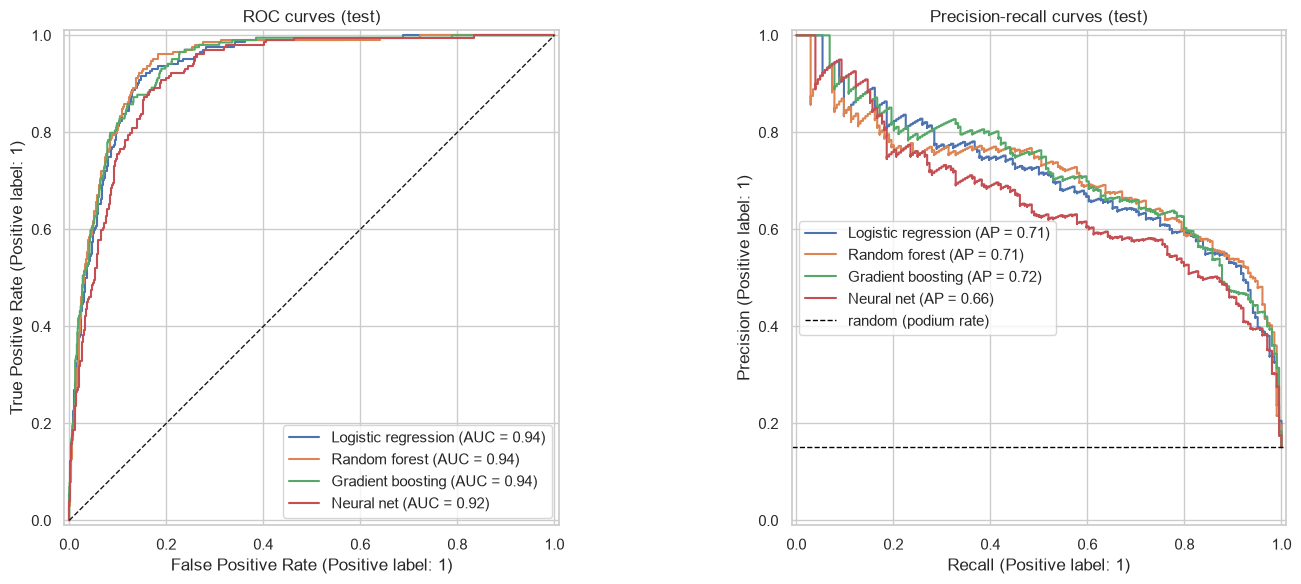

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for family, name in final_models.items():
    RocCurveDisplay.from_estimator(fitted[name], X_test, y_test, name=family, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(fitted[name], X_test, y_test, name=family, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="random (podium rate)")
axes[0].set_title("ROC curves (test)")
axes[1].set_title("Precision-recall curves (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Experiments

All experiments use the final logistic regression. Preprocessing removes all missing values and scales every feature to mean 0 and standard deviation 1.

In [46]:
final_model = fitted["Logistic regression"]

X_tr_prepared = pd.DataFrame(final_model[:-1].transform(X_tr), columns=FEATURES, index=X_tr.index)
pd.DataFrame({
    "missing before": X_tr.isna().sum(), "mean before": X_tr.mean(), "std before": X_tr.std(),
    "missing after": X_tr_prepared.isna().sum(), "mean after": X_tr_prepared.mean(), "std after": X_tr_prepared.std(),
}).round(2)

,missing before,mean before,std before,missing after,mean after,std after
grid_pos,0,11.18,6.23,0,-0.0,1.0
q1_gap_pct,122,1.78,1.82,0,-0.0,1.0
grid_penalty,20,-0.00,1.54,0,0.0,1.0
has_quali,0,1.00,0.05,0,-0.0,1.0
drv_podium_rate_last5,75,0.14,0.25,0,0.0,1.0
drv_avg_finish_last5,75,11.08,4.51,0,0.0,1.0
drv_races_before,0,92.90,79.17,0,0.0,1.0
drv_career_podium_rate,75,0.13,0.17,0,0.0,1.0
con_podium_rate_last5,35,0.14,0.23,0,0.0,1.0
con_best_finish_last5,35,8.60,4.60,0,-0.0,1.0


### 8.1 Feature-group ablation

Grid is the most important group (validation PR-AUC drops by 0.069 without it). The other groups cost 0.003-0.012 because they overlap.

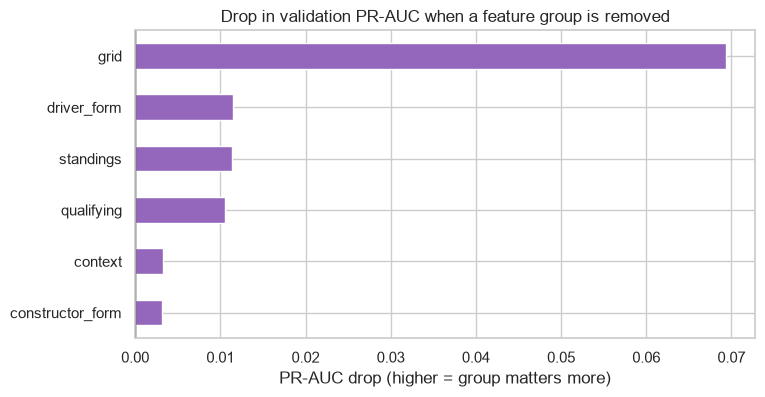

,val ROC-AUC,val PR-AUC,PR-AUC drop
none (all features),0.929,0.739,0.000
grid,0.898,0.669,0.069
qualifying,0.926,0.728,0.011
driver_form,0.928,0.727,0.012
constructor_form,0.928,0.735,0.003
standings,0.927,0.727,0.011
context,0.929,0.735,0.003


In [47]:
def val_scores(model, columns=FEATURES):
    prob = model.predict_proba(X_val[columns])[:, 1]
    return {"val ROC-AUC": roc_auc_score(y_val, prob), "val PR-AUC": average_precision_score(y_val, prob)}

def fit_without(columns):
    model = make_model(LogisticRegression(max_iter=1000)).fit(X_tr[columns], y_tr)
    return val_scores(model, columns)

ablation = {"none (all features)": fit_without(FEATURES)}
for group, cols in FEATURE_GROUPS.items():
    ablation[group] = fit_without([c for c in FEATURES if c not in cols])
ablation = pd.DataFrame(ablation).T
ablation["PR-AUC drop"] = ablation.loc["none (all features)", "val PR-AUC"] - ablation["val PR-AUC"]

ablation["PR-AUC drop"].drop("none (all features)").sort_values().plot.barh(
    color="tab:purple", figsize=(8, 4), title="Drop in validation PR-AUC when a feature group is removed")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("PR-AUC drop (higher = group matters more)")
plt.show()
ablation.round(3)

### 8.2 Preprocessing-order experiments

Fitting preprocessing on all data before the split changes the medians (leakage) and moves validation PR-AUC from 0.7386 to 0.7368. Scaling before imputing makes no difference.

In [48]:
prep_all = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(pd.concat([X_tr, X_val, X_test]))
lr_all = LogisticRegression(max_iter=1000).fit(prep_all.transform(X_tr), y_tr)
prob_leaky = lr_all.predict_proba(prep_all.transform(X_val))[:, 1]

scale_first = make_pipeline(StandardScaler(), SimpleImputer(strategy="median"), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)

pd.DataFrame({
    "Impute -> scale, fitted on train only (ours)": val_scores(final_model),
    "A: impute -> scale, fitted on all data before split (leaky)": {
        "val ROC-AUC": roc_auc_score(y_val, prob_leaky), "val PR-AUC": average_precision_score(y_val, prob_leaky)},
    "B: scale -> impute, fitted on train only": val_scores(scale_first),
}).T.round(4)

,val ROC-AUC,val PR-AUC
"Impute -> scale, fitted on train only (ours)",0.9292,0.7386
"A: impute -> scale, fitted on all data before split (leaky)",0.9292,0.7368
"B: scale -> impute, fitted on train only",0.9291,0.7386


In [49]:
medians = pd.DataFrame({"median (train only)": final_model[0].statistics_,
                        "median (all data, leaky)": prep_all[0].statistics_}, index=FEATURES)
medians[medians.iloc[:, 0] != medians.iloc[:, 1]].round(3)

,median (train only),"median (all data, leaky)"
q1_gap_pct,1.342,1.223
drv_avg_finish_last5,11.400,11.200
drv_races_before,70.000,82.000
drv_career_podium_rate,0.049,0.049
field_size,21.000,20.000


## 9. Explainability (XAI)

Explanations of the final model on the test set. They show what the model relies on, not what causes podiums.

### 9.1 Global: permutation importance

Grid position dominates (about 0.35 drop in PR-AUC), followed by the team's recent best finish, the grid penalty and the driver's recent podium rate.

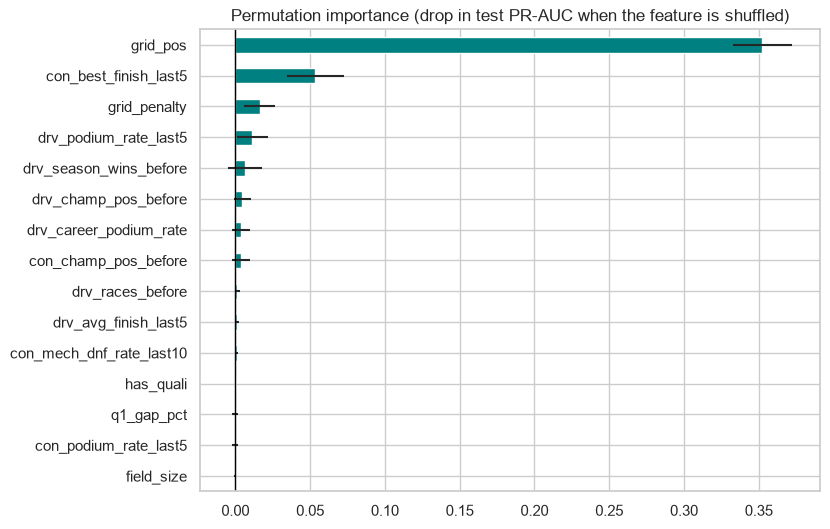

In [50]:
perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision", n_repeats=10, random_state=SEED)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

perm_imp.plot.barh(xerr=pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index], color="teal", figsize=(8, 6),
                   title="Permutation importance (drop in test PR-AUC when the feature is shuffled)")
plt.axvline(0, color="black", linewidth=1)
plt.show()

### 9.2 Global: SHAP

A front grid slot, strong recent team and driver form and a large grid penalty push predictions towards a podium.

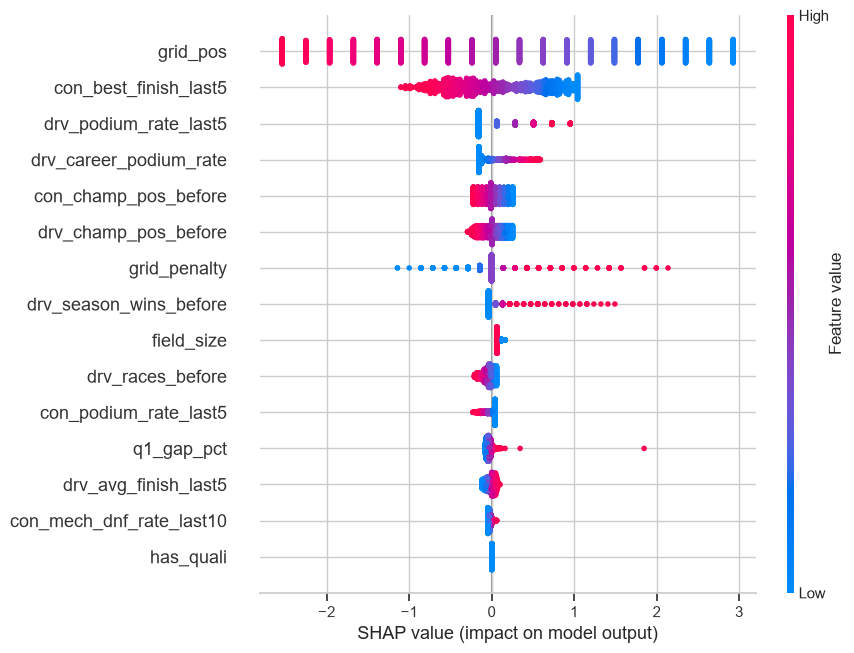

In [51]:
X_test_prepared = final_model[:-1].transform(X_test)
background = shap.maskers.Independent(X_tr_prepared, max_samples=len(X_tr_prepared))
explainer = shap.LinearExplainer(final_model[-1], background)
shap_values = explainer(X_test_prepared)
shap_values.feature_names = FEATURES
shap_values.data = final_model[0].transform(X_test)

shap.plots.beeswarm(shap_values, max_display=15)

### 9.3 Local: SHAP and LIME for one prediction

Max Verstappen at the 2022 Belgian GP started 14th after a grid penalty and won. The model gave him 57%, mainly because of the grid penalty and his team and driver form, and LIME agrees.

In [52]:
test_info = (test[["raceId", "driverId", "grid_pos", "grid_penalty", TARGET]]
             .merge(clean["drivers"][["driverId", "forename", "surname"]], on="driverId", how="left")
             .merge(clean["races"][["raceId", "year", "name"]], on="raceId", how="left"))
test_info["predicted probability"] = final_model.predict_proba(X_test)[:, 1]

row = test_info[test_info[TARGET] == 1]["grid_penalty"].idxmax()
test_info.loc[[row], ["year", "name", "forename", "surname", "grid_pos", "grid_penalty", TARGET, "predicted probability"]]

,year,name,forename,surname,grid_pos,grid_penalty,podium,predicted probability
266,2022,Belgian Grand Prix,Max,Verstappen,14,13.0,1,0.573939


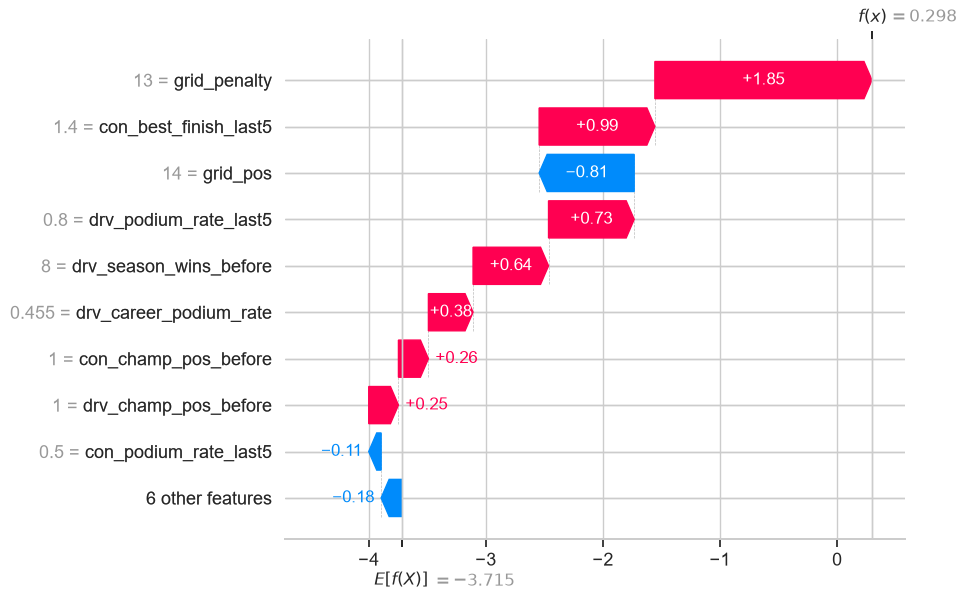

In [53]:
shap.plots.waterfall(shap_values[row], max_display=10)

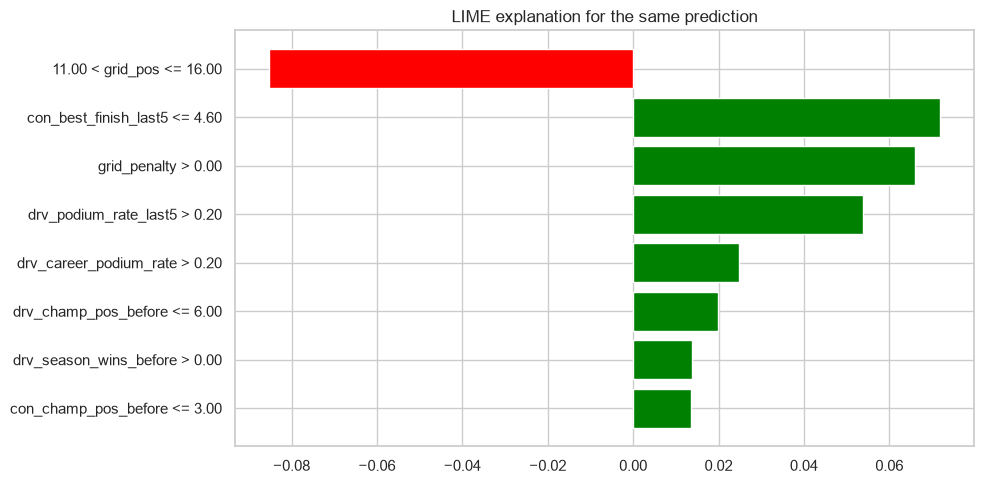

In [54]:
lime_explainer = LimeTabularExplainer(final_model[0].transform(X_tr), feature_names=FEATURES,
                                      class_names=["no podium", "podium"], mode="classification", random_state=SEED)
predict = lambda values: final_model.predict_proba(pd.DataFrame(values, columns=FEATURES))
lime_exp = lime_explainer.explain_instance(final_model[0].transform(X_test)[row], predict, num_features=8)

lime_exp.as_pyplot_figure()
plt.title("LIME explanation for the same prediction")
plt.tight_layout()
plt.show()

## 10. Inference function

`predict_podium` returns the podium probability, a yes/no prediction (threshold 0.28) and the list of imputed features. Norris at the 2024 Abu Dhabi GP gets 62.9% with the complete record and 51.9% with 5 features missing.

In [55]:
FINAL_THRESHOLD = thresholds["Logistic regression"]

def predict_podium(record, model=final_model, threshold=FINAL_THRESHOLD):
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f"Unknown feature names: {unknown}")

    row = pd.DataFrame([record]).reindex(columns=FEATURES)

    probability = model.predict_proba(row)[0, 1]
    return {
        "podium_probability": round(float(probability), 3),
        "podium_prediction": int(probability >= threshold),
        "threshold": round(threshold, 2),
        "filled_with_training_median": [f for f in FEATURES if pd.isna(row.loc[0, f])],
    }

In [56]:
pos = test_info[(test_info["year"] == 2024) & (test_info["name"] == "Abu Dhabi Grand Prix")
                & (test_info["surname"] == "Norris")].index[0]
complete_record = X_test.iloc[pos].to_dict()

print("Input:", {k: round(v, 3) for k, v in complete_record.items()})
print("Output:", predict_podium(complete_record))
print("Actual result: podium =", y_test.iloc[pos])

Input: {'grid_pos': 1.0, 'q1_gap_pct': 0.456, 'grid_penalty': 0.0, 'has_quali': 1.0, 'drv_podium_rate_last5': 0.2, 'drv_avg_finish_last5': 5.6, 'drv_races_before': 127.0, 'drv_career_podium_rate': 0.197, 'con_podium_rate_last5': 0.2, 'con_best_finish_last5': 4.2, 'con_mech_dnf_rate_last10': 0.0, 'drv_champ_pos_before': 2.0, 'drv_season_wins_before': 3.0, 'con_champ_pos_before': 1.0, 'field_size': 20.0}
Output: {'podium_probability': 0.629, 'podium_prediction': 1, 'threshold': 0.28, 'filled_with_training_median': []}
Actual result: podium = 1


In [57]:
partial_record = {k: v for k, v in complete_record.items()
                  if k not in ["q1_gap_pct", "grid_penalty", "has_quali", "drv_champ_pos_before", "con_champ_pos_before"]}

print("Input:", {k: round(v, 3) for k, v in partial_record.items()})
print("Output:", predict_podium(partial_record))

Input: {'grid_pos': 1.0, 'drv_podium_rate_last5': 0.2, 'drv_avg_finish_last5': 5.6, 'drv_races_before': 127.0, 'drv_career_podium_rate': 0.197, 'con_podium_rate_last5': 0.2, 'con_best_finish_last5': 4.2, 'con_mech_dnf_rate_last10': 0.0, 'drv_season_wins_before': 3.0, 'field_size': 20.0}
Output: {'podium_probability': 0.519, 'podium_prediction': 1, 'threshold': 0.28, 'filled_with_training_median': ['q1_gap_pct', 'grid_penalty', 'has_quali', 'drv_champ_pos_before', 'con_champ_pos_before']}


## Known limitations

Qualifying-coverage drift and era sensitivity (regulation changes) limit the model, the validation and test sets are small, and correlated features should be read as a group. The explanations are not causal.